# EDA

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load train.csv in chunks
chunks = []

for chunk in pd.read_csv("train.csv", chunksize=100000):
    chunks.append(chunk)

train = pd.concat(chunks, ignore_index=True)

# Load the smaller files normally
stores = pd.read_csv("stores.csv")
holidays = pd.read_csv("holidays_events.csv")

print("Train shape:", train.shape)
print("Stores shape:", stores.shape)
print("Holidays shape:", holidays.shape)

Train shape: (125497040, 6)
Stores shape: (54, 5)
Holidays shape: (350, 6)


In [4]:
print("Train columns:")
print(train.columns.tolist())

print("\nStores columns:")
print(stores.columns.tolist())

print("\nHolidays columns:")
print(holidays.columns.tolist())

print("\nTrain data types:")
print(train.dtypes)

print("\nFirst 5 rows:")
display(train.head())

print("\nStores:")
display(stores.head())

print("\nHolidays:")
display(holidays.head())

Train columns:
['id', 'date', 'store_nbr', 'item_nbr', 'unit_sales', 'onpromotion']

Stores columns:
['store_nbr', 'city', 'state', 'type', 'cluster']

Holidays columns:
['date', 'type', 'locale', 'locale_name', 'description', 'transferred']

Train data types:
id               int64
date            object
store_nbr        int64
item_nbr         int64
unit_sales     float64
onpromotion     object
dtype: object

First 5 rows:


,id,date,store_nbr,item_nbr,unit_sales,onpromotion
0,0,2013-01-01,25,103665,7.0,NaN
1,1,2013-01-01,25,105574,1.0,NaN
2,2,2013-01-01,25,105575,2.0,NaN
3,3,2013-01-01,25,108079,1.0,NaN
4,4,2013-01-01,25,108701,1.0,NaN



Stores:


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4



Holidays:


,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False


In [5]:
print("===== TRAIN DATA =====")

print("Number of rows:", len(train))
print("Number of stores:", train["store_nbr"].nunique())
print("Number of items:", train["item_nbr"].nunique())

print("\nDate range:")
print("Start:", train["date"].min())
print("End:", train["date"].max())

print("\nUnit sales:")
print("Minimum:", train["unit_sales"].min())
print("Maximum:", train["unit_sales"].max())
print("Mean:", train["unit_sales"].mean())

print("\nMissing values:")
print(train.isna().sum())

print("\n===== STORES =====")
print("Cities:", stores["city"].nunique())
print("States:", stores["state"].nunique())
print("Store types:", stores["type"].unique())
print("Clusters:", stores["cluster"].nunique())

print("\n===== HOLIDAYS =====")
print("Holiday types:", holidays["type"].unique())
print("Locales:", holidays["locale"].unique())
print("Transferred holidays:", holidays["transferred"].value_counts())

===== TRAIN DATA =====
Number of rows: 125497040
Number of stores: 54
Number of items: 4036

Date range:
Start: 2013-01-01
End: 2017-08-15

Unit sales:
Minimum: -15372.0
Maximum: 89440.0
Mean: 8.554865268438204

Missing values:
id                    0
date                  0
store_nbr             0
item_nbr              0
unit_sales            0
onpromotion    21657651
dtype: int64

===== STORES =====
Cities: 22
States: 16
Store types: ['D' 'B' 'C' 'E' 'A']
Clusters: 17

===== HOLIDAYS =====
Holiday types: ['Holiday' 'Transfer' 'Additional' 'Bridge' 'Work Day' 'Event']
Locales: ['Local' 'Regional' 'National']
Transferred holidays: transferred
False    338
True      12
Name: count, dtype: int64


In [6]:
# Sales distribution statistics

sales = train["unit_sales"]

print("===== SALES DISTRIBUTION =====")

print("Percentiles:")
print(sales.quantile([0, 0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.00]))

print("\nNegative sales:", (sales < 0).sum())
print("Zero sales:", (sales == 0).sum())
print("Positive sales:", (sales > 0).sum())

print("\nPercentage of negative sales:", (sales < 0).mean() * 100)
print("Percentage of zero sales:", (sales == 0).mean() * 100)
print("Percentage of positive sales:", (sales > 0).mean() * 100)

===== SALES DISTRIBUTION =====
Percentiles:
0.00   -15372.0
0.01        1.0
0.05        1.0
0.25        2.0
0.50        4.0
0.75        9.0
0.90       18.0
0.95       29.0
0.99       71.0
1.00    89440.0
Name: unit_sales, dtype: float64

Negative sales: 7795
Zero sales: 0
Positive sales: 125489245

Percentage of negative sales: 0.006211301876123931
Percentage of zero sales: 0.0
Percentage of positive sales: 99.99378869812388


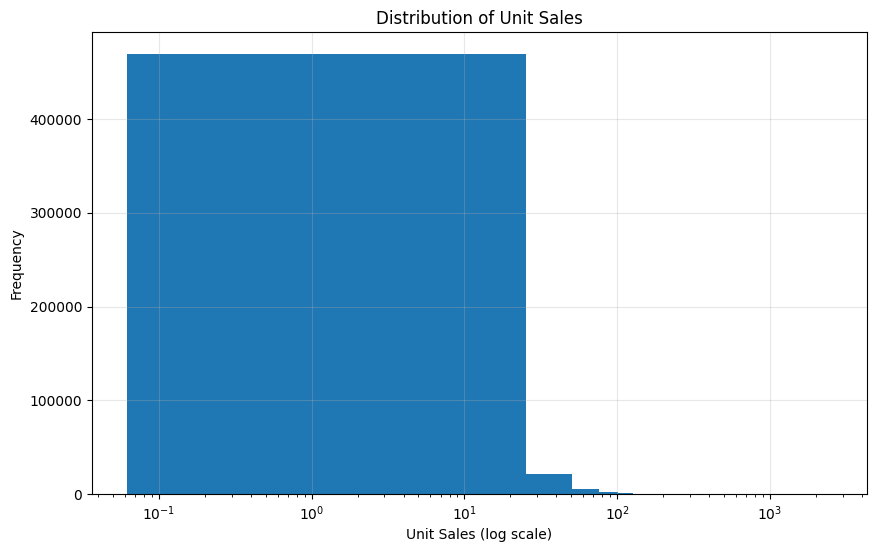

In [7]:
import matplotlib.pyplot as plt

# Take a sample for visualization to keep plotting fast
sales_sample = train["unit_sales"].sample(
    n=min(500000, len(train)),
    random_state=42
)

plt.figure(figsize=(10, 6))

plt.hist(sales_sample[sales_sample > 0], bins=100)

plt.xscale("log")
plt.xlabel("Unit Sales (log scale)")
plt.ylabel("Frequency")
plt.title("Distribution of Unit Sales")
plt.grid(alpha=0.3)

plt.show()

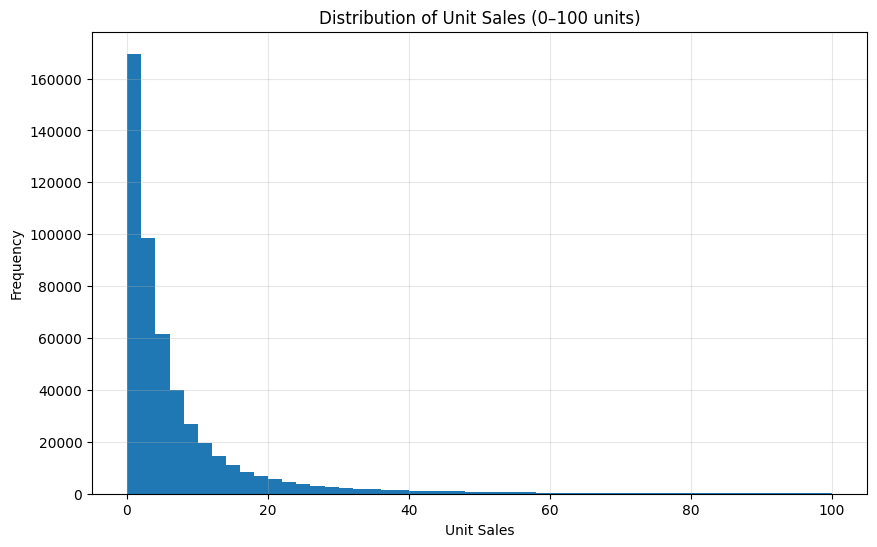

In [8]:
plt.figure(figsize=(10, 6))

sales_sample = train["unit_sales"].sample(
    n=min(500000, len(train)),
    random_state=42
)

# Keep only normal positive sales for this visualization
sales_plot = sales_sample[
    (sales_sample > 0) & (sales_sample <= 100)
]

plt.hist(sales_plot, bins=50)

plt.xlabel("Unit Sales")
plt.ylabel("Frequency")
plt.title("Distribution of Unit Sales (0–100 units)")
plt.grid(alpha=0.3)

plt.show()

In [9]:
# Examine negative sales records

negative_sales = train[train["unit_sales"] < 0]

print("Number of negative records:", len(negative_sales))

print("\nNegative sales statistics:")
print(negative_sales["unit_sales"].describe())

print("\nSample negative sales records:")
display(negative_sales.head(20))


Number of negative records: 7795

Negative sales statistics:
count     7795.000000
mean       -18.419606
std        242.254294
min     -15372.000000
25%         -4.000000
50%         -1.000000
75%         -1.000000
max         -0.002000
Name: unit_sales, dtype: float64

Sample negative sales records:


,id,date,store_nbr,item_nbr,unit_sales,onpromotion
10655,10655,2013-01-02,10,456875,-3.000,NaN
46867,46867,2013-01-03,5,559044,-1.000,NaN
50970,50970,2013-01-03,9,365138,-3.000,NaN
71807,71807,2013-01-03,41,812716,-19.000,NaN
71992,71992,2013-01-03,41,1004551,-27.000,NaN
75255,75255,2013-01-03,46,208530,-8.080,NaN
91163,91163,2013-01-04,9,457574,-8.516,NaN
106658,106658,2013-01-04,34,586824,-2.000,NaN
111811,111811,2013-01-04,41,956012,-1.000,NaN
111813,111813,2013-01-04,41,956014,-1.000,NaN


In [10]:
print("\nNegative sales by store:")
display(
    negative_sales.groupby("store_nbr")["unit_sales"]
    .agg(["count", "min", "max", "mean"])
    .sort_values("count", ascending=False)
)

print("\nNegative sales by item:")
display(
    negative_sales.groupby("item_nbr")["unit_sales"]
    .agg(["count", "min", "max", "mean"])
    .sort_values("count", ascending=False)
    .head(20)
)


Negative sales by store:


,count,min,max,mean
store_nbr,,,,
18,483,-15372.000,-0.060,-38.226437
44,414,-1806.000,-0.002,-10.472580
49,362,-2400.000,-0.088,-14.132807
7,320,-1943.000,-0.166,-12.075941
3,319,-448.000,-0.041,-11.387337
51,290,-84.000,-0.061,-3.715541
8,272,-992.000,-0.004,-19.621522
1,267,-276.000,-0.041,-5.944251
2,264,-1797.000,-0.009,-49.002568



Negative sales by item:


,count,min,max,mean
item_nbr,,,,
172995,69,-6.000,-1.000,-2.463768
2006144,66,-2.000,-1.000,-1.060606
1229440,64,-25.000,-1.000,-1.625000
1410850,58,-2.000,-1.000,-1.034483
1464240,41,-24.000,-1.000,-6.024390
250782,38,-5.000,-1.000,-1.105263
957096,37,-40.000,-1.000,-3.135135
1049595,35,-6.000,-1.000,-2.771429
1456952,28,-2.000,-1.000,-1.178571


In [11]:
print("\nNegative sales by store:")
display(
    negative_sales.groupby("store_nbr")["unit_sales"]
    .agg(["count", "min", "max", "mean"])
    .sort_values("count", ascending=False)
)

print("\nNegative sales by item:")
display(
    negative_sales.groupby("item_nbr")["unit_sales"]
    .agg(["count", "min", "max", "mean"])
    .sort_values("count", ascending=False)
    .head(20)
)


Negative sales by store:


,count,min,max,mean
store_nbr,,,,
18,483,-15372.000,-0.060,-38.226437
44,414,-1806.000,-0.002,-10.472580
49,362,-2400.000,-0.088,-14.132807
7,320,-1943.000,-0.166,-12.075941
3,319,-448.000,-0.041,-11.387337
51,290,-84.000,-0.061,-3.715541
8,272,-992.000,-0.004,-19.621522
1,267,-276.000,-0.041,-5.944251
2,264,-1797.000,-0.009,-49.002568



Negative sales by item:


,count,min,max,mean
item_nbr,,,,
172995,69,-6.000,-1.000,-2.463768
2006144,66,-2.000,-1.000,-1.060606
1229440,64,-25.000,-1.000,-1.625000
1410850,58,-2.000,-1.000,-1.034483
1464240,41,-24.000,-1.000,-6.024390
250782,38,-5.000,-1.000,-1.105263
957096,37,-40.000,-1.000,-3.135135
1049595,35,-6.000,-1.000,-2.771429
1456952,28,-2.000,-1.000,-1.178571


In [12]:
# Daily total sales
daily_sales = (
    train.groupby("date")["unit_sales"]
    .sum()
    .reset_index()
)

daily_sales["date"] = pd.to_datetime(daily_sales["date"])

print("Number of days:", len(daily_sales))
print("\nFirst 5 days:")
display(daily_sales.head())

print("\nLast 5 days:")
display(daily_sales.tail())

Number of days: 1684

First 5 days:


,date,unit_sales
0,2013-01-01,2511.619
1,2013-01-02,496092.418
2,2013-01-03,361429.231
3,2013-01-04,354459.677
4,2013-01-05,477350.121



Last 5 days:


,date,unit_sales
1679,2017-08-11,826373.722
1680,2017-08-12,792630.535
1681,2017-08-13,865639.677
1682,2017-08-14,760922.406
1683,2017-08-15,762661.936


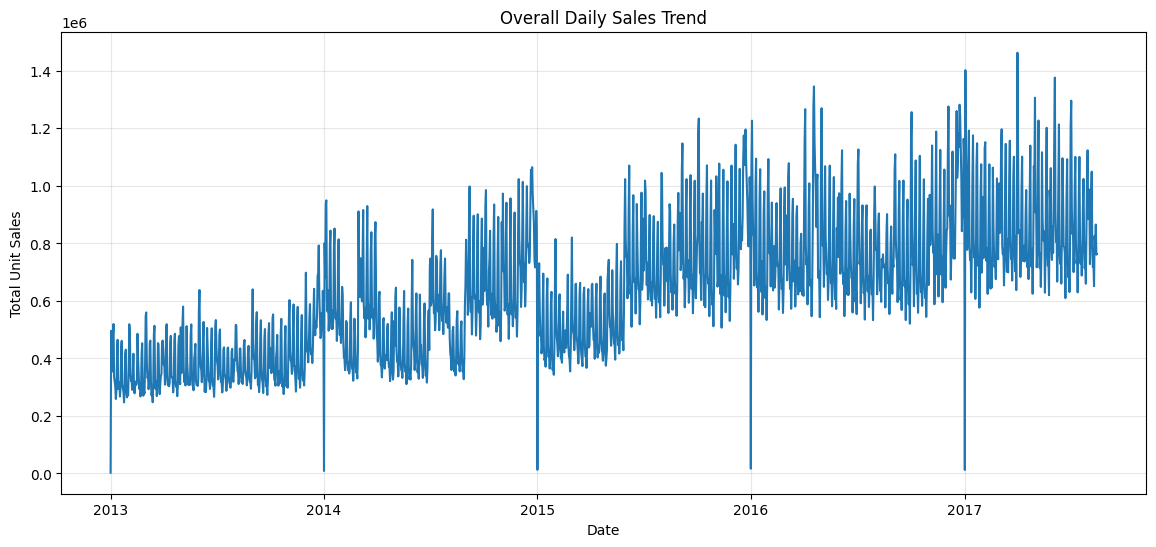

In [13]:
plt.figure(figsize=(14, 6))

plt.plot(
    daily_sales["date"],
    daily_sales["unit_sales"]
)

plt.xlabel("Date")
plt.ylabel("Total Unit Sales")
plt.title("Overall Daily Sales Trend")
plt.grid(alpha=0.3)

plt.show()

In [14]:
# Add day of week
daily_sales["day_of_week"] = daily_sales["date"].dt.day_name()

# Order days correctly
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekly_pattern = (
    daily_sales.groupby("day_of_week")["unit_sales"]
    .mean()
    .reindex(day_order)
)

print("Average sales by day of week:")
display(weekly_pattern)

Average sales by day of week:


day_of_week
Monday       617479.929934
Tuesday      569916.489993
Wednesday    593244.190965
Thursday     505256.688612
Friday       579573.986125
Saturday     772147.340838
Sunday       825218.075771
Name: unit_sales, dtype: float64

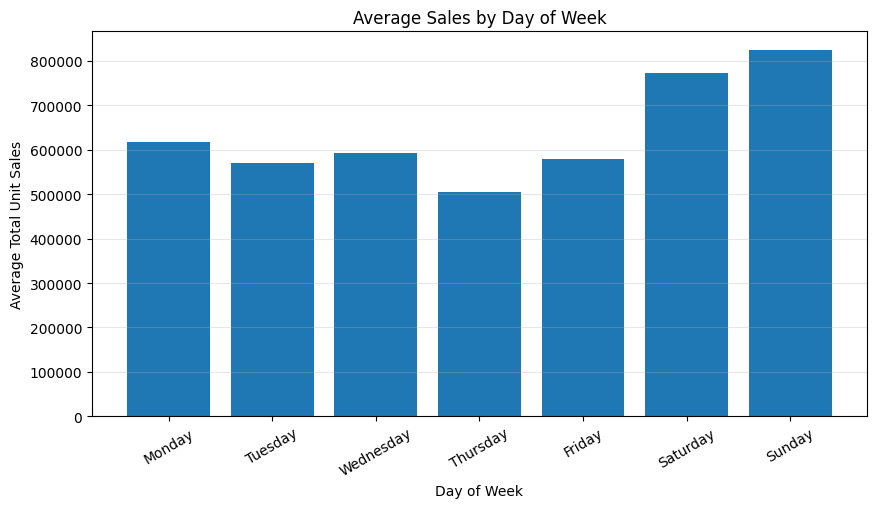

In [15]:
plt.figure(figsize=(10, 5))

plt.bar(weekly_pattern.index, weekly_pattern.values)

plt.xlabel("Day of Week")
plt.ylabel("Average Total Unit Sales")
plt.title("Average Sales by Day of Week")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [16]:
# Add month
daily_sales["month"] = daily_sales["date"].dt.month

monthly_pattern = (
    daily_sales.groupby("month")["unit_sales"]
    .mean()
)

print("Average sales by month:")
display(monthly_pattern)

Average sales by month:


month
1     609302.427826
2     571895.137866
3     627280.426773
4     604434.377091
5     608923.187230
6     630029.288595
7     666858.404401
8     600520.495226
9     645613.966011
10    645808.922815
11    669464.117255
12    808541.583939
Name: unit_sales, dtype: float64

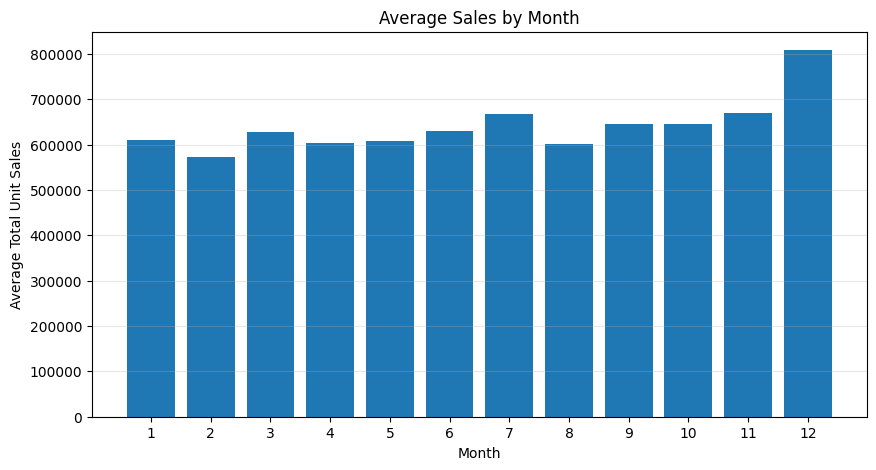

In [17]:
plt.figure(figsize=(10, 5))

plt.bar(
    monthly_pattern.index,
    monthly_pattern.values
)

plt.xlabel("Month")
plt.ylabel("Average Total Unit Sales")
plt.title("Average Sales by Month")
plt.xticks(range(1, 13))
plt.grid(axis="y", alpha=0.3)

plt.show()

In [18]:
store_sales = (
    train.groupby("store_nbr")["unit_sales"]
    .agg(["sum", "mean", "count"])
    .sort_values("sum", ascending=False)
)

print("Sales by store:")
display(store_sales)

Sales by store:


,sum,mean,count
store_nbr,,,
44,6.208754e+07,17.673206,3513089
45,5.449801e+07,15.641273,3484244
47,5.094831e+07,14.735988,3457407
3,5.048190e+07,14.842100,3401264
49,4.342009e+07,12.990183,3342531
46,4.189605e+07,12.491779,3353890
48,3.593313e+07,11.102387,3236523
51,3.291148e+07,11.118628,2960031
8,3.049134e+07,9.349775,3261184


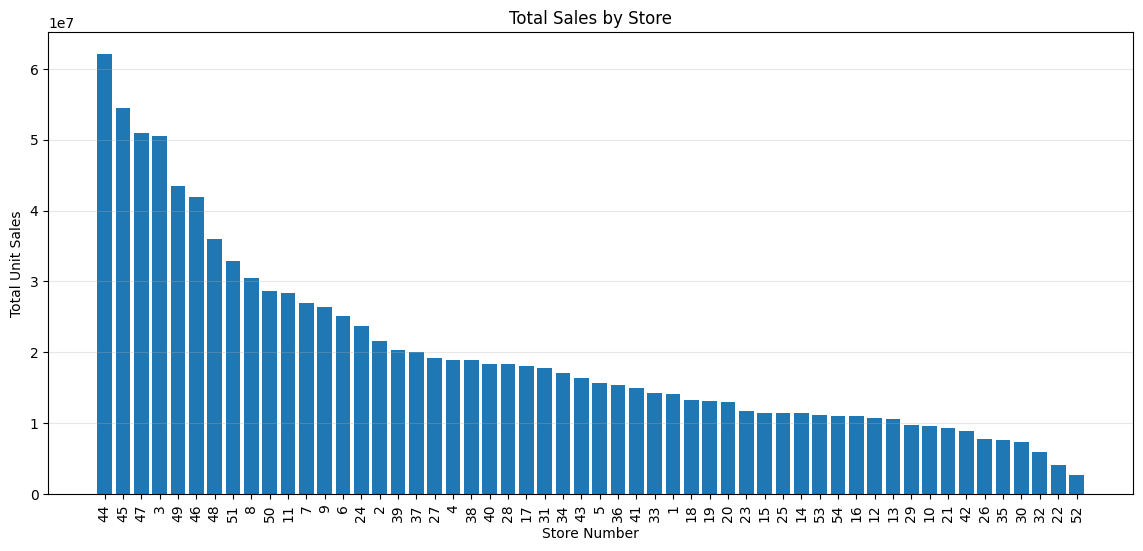

In [19]:
plt.figure(figsize=(14, 6))

plt.bar(
    store_sales.index.astype(str),
    store_sales["sum"]
)

plt.xlabel("Store Number")
plt.ylabel("Total Unit Sales")
plt.title("Total Sales by Store")
plt.xticks(rotation=90)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [20]:
item_sales = (
    train.groupby("item_nbr")["unit_sales"]
    .agg(["sum", "mean", "count"])
    .sort_values("sum", ascending=False)
)

print("Number of items:", len(item_sales))

print("\nTop 20 items by total sales:")
display(item_sales.head(20))

print("\nBottom 20 items by total sales:")
display(item_sales.tail(20))

Number of items: 4036

Top 20 items by total sales:


,sum,mean,count
item_nbr,,,
1503844,6.264200e+06,227.929984,27483
1047679,5.512875e+06,68.302194,80713
1473474,4.990323e+06,103.884977,48037
364606,4.416426e+06,53.013228,83308
819932,4.410943e+06,58.699870,75144
1463992,4.408545e+06,88.715614,49693
807493,4.321424e+06,54.095562,79885
265559,4.112827e+06,49.524089,83047
502331,3.703350e+06,44.364780,83475



Bottom 20 items by total sales:


,sum,mean,count
item_nbr,,,
2123711,23.0,1.916667,12
2123859,22.0,2.200000,10
2121690,21.0,1.105263,19
2126842,19.0,1.583333,12
2123863,17.0,1.416667,12
2011448,15.0,1.500000,10
2011459,13.0,1.444444,9
2116132,12.0,1.200000,10
2011468,12.0,1.333333,9


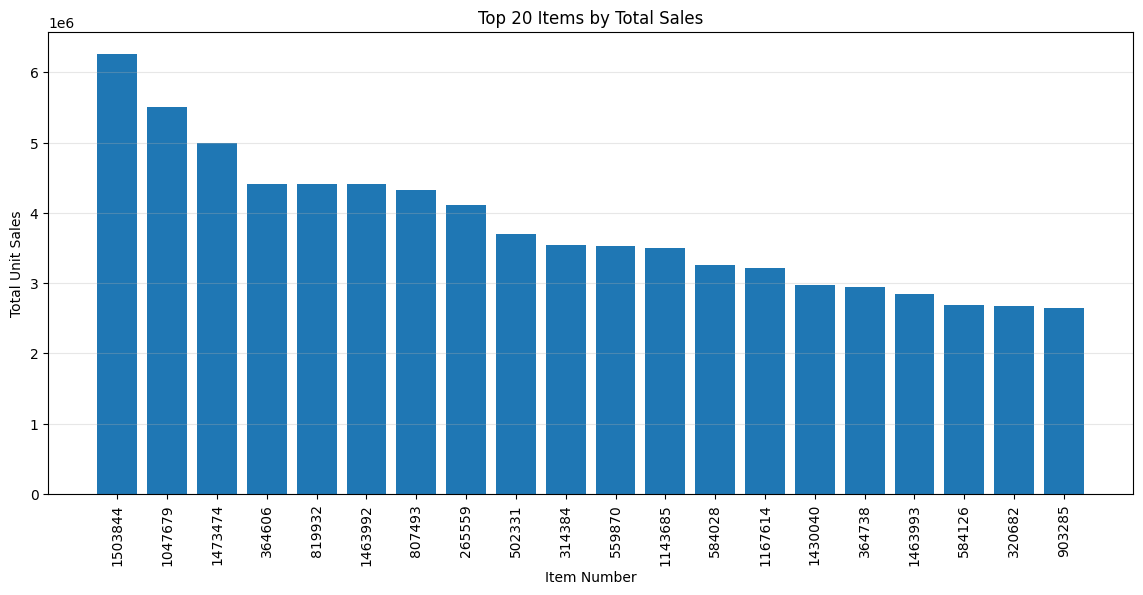

In [21]:
top_items = item_sales.head(20)

plt.figure(figsize=(14, 6))

plt.bar(
    top_items.index.astype(str),
    top_items["sum"]
)

plt.xlabel("Item Number")
plt.ylabel("Total Unit Sales")
plt.title("Top 20 Items by Total Sales")
plt.xticks(rotation=90)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [22]:
store_item_count = train.groupby(
    ["store_nbr", "item_nbr"]
).ngroups

possible_combinations = 54 * 4036

print("Possible store-item combinations:", possible_combinations)
print("Actual store-item combinations:", store_item_count)

coverage = (store_item_count / possible_combinations) * 100

print("Coverage:", coverage, "%")

Possible store-item combinations: 217944
Actual store-item combinations: 174685
Coverage: 80.15132327570385 %


In [23]:
combo_counts = (
    train.groupby(["store_nbr", "item_nbr"])
    .size()
)

print("Observations per store-item combination:")
print(combo_counts.describe())

print("\nMinimum observations:", combo_counts.min())
print("Maximum observations:", combo_counts.max())
print("Median observations:", combo_counts.median())

Observations per store-item combination:
count    174685.000000
mean        718.419097
std         514.831287
min           1.000000
25%         245.000000
50%         651.000000
75%        1133.000000
max        1679.000000
dtype: float64

Minimum observations: 1
Maximum observations: 1679
Median observations: 651.0


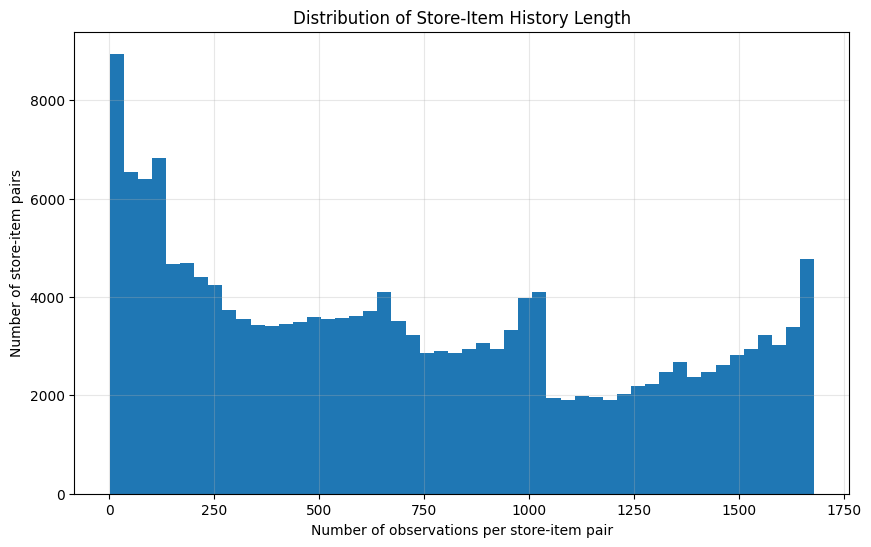

In [24]:
plt.figure(figsize=(10, 6))

plt.hist(
    combo_counts,
    bins=50
)

plt.xlabel("Number of observations per store-item pair")
plt.ylabel("Number of store-item pairs")
plt.title("Distribution of Store-Item History Length")
plt.grid(alpha=0.3)

plt.show()

In [25]:
print("Unique onpromotion values:")
print(train["onpromotion"].value_counts(dropna=False))

Unique onpromotion values:
onpromotion
False    96028767
NaN      21657651
True      7810622
Name: count, dtype: int64


In [26]:
promotion_sales = (
    train.groupby("onpromotion", dropna=False)["unit_sales"]
    .agg(["count", "mean", "median", "sum"])
)

print(promotion_sales)

                count       mean  median           sum
onpromotion                                           
NaN          21657651   8.852925     4.0  1.917336e+08
False        96028767   8.088135     4.0  7.766937e+08
True          7810622  13.466666     6.0  1.051830e+08


In [28]:
promo_mean = train.loc[
    train["onpromotion"] == True, "unit_sales"
].mean()

nonpromo_mean = train.loc[
    train["onpromotion"] == False, "unit_sales"
].mean()

print("Average sales when promoted:", promo_mean)
print("Average sales when not promoted:", nonpromo_mean)

print(
    "Difference:",
    ((promo_mean - nonpromo_mean) / nonpromo_mean) * 100,
    "%"
)

Average sales when promoted: 13.466666121008032
Average sales when not promoted: 8.088135379593076
Difference: 66.49901972443934 %


In [29]:
# Convert dates
holidays["date"] = pd.to_datetime(holidays["date"])
daily_sales["date"] = pd.to_datetime(daily_sales["date"])

# Look at holiday/event types
print("Holiday types:")
print(holidays["type"].value_counts())

print("\nHoliday locales:")
print(holidays["locale"].value_counts())

print("\nTransferred holidays:")
display(
    holidays[holidays["transferred"] == True]
)

Holiday types:
type
Holiday       221
Event          56
Additional     51
Transfer       12
Bridge          5
Work Day        5
Name: count, dtype: int64

Holiday locales:
locale
National    174
Local       152
Regional     24
Name: count, dtype: int64

Transferred holidays:


,date,type,locale,locale_name,description,transferred
19,2012-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
72,2013-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
135,2014-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
255,2016-05-24,Holiday,National,Ecuador,Batalla de Pichincha,True
266,2016-07-25,Holiday,Local,Guayaquil,Fundacion de Guayaquil,True
268,2016-08-10,Holiday,National,Ecuador,Primer Grito de Independencia,True
297,2017-01-01,Holiday,National,Ecuador,Primer dia del ano,True
303,2017-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,True
312,2017-05-24,Holiday,National,Ecuador,Batalla de Pichincha,True
324,2017-08-10,Holiday,National,Ecuador,Primer Grito de Independencia,True


In [30]:
print("===== STORE CHARACTERISTICS =====")

print("\nStores by type:")
print(stores["type"].value_counts().sort_index())

print("\nStores by state:")
print(stores["state"].value_counts())

print("\nStores by city:")
print(stores["city"].value_counts())

print("\nStores by cluster:")
print(stores["cluster"].value_counts().sort_index())

===== STORE CHARACTERISTICS =====

Stores by type:
type
A     9
B     8
C    15
D    18
E     4
Name: count, dtype: int64

Stores by state:
state
Pichincha                         19
Guayas                            11
Azuay                              3
Santo Domingo de los Tsachilas     3
Manabi                             3
Los Rios                           2
Cotopaxi                           2
Tungurahua                         2
El Oro                             2
Bolivar                            1
Imbabura                           1
Chimborazo                         1
Pastaza                            1
Santa Elena                        1
Loja                               1
Esmeraldas                         1
Name: count, dtype: int64

Stores by city:
city
Quito            18
Guayaquil         8
Cuenca            3
Santo Domingo     3
Latacunga         2
Machala           2
Manta             2
Ambato            2
Cayambe           1
Riobamba          1
Ibarra        

In [31]:
store_type_sales = (
    train.merge(
        stores[["store_nbr", "type"]],
        on="store_nbr",
        how="left"
    )
    .groupby("type")["unit_sales"]
    .agg(["count", "mean", "sum"])
)

display(store_type_sales)

,count,mean,sum
type,,,
A,26830862,13.158124,3.530438e+08
B,17877340,8.124713,1.452483e+08
C,25908837,6.346655,1.644345e+08
D,46801370,7.501134,3.510633e+08
E,8078631,7.404773,5.982042e+07


In [32]:
# Create a set of dates that have holiday/event records
holiday_dates = set(
    holidays.loc[
        holidays["transferred"] == False,
        "date"
    ]
)

daily_sales["is_holiday_event"] = daily_sales["date"].isin(holiday_dates)

holiday_sales = (
    daily_sales.groupby("is_holiday_event")["unit_sales"]
    .agg(["count", "mean", "median", "sum"])
)

print(holiday_sales)

                  count           mean      median           sum
is_holiday_event                                                
False              1441  627084.933584  624910.026  9.036294e+08
True                243  699509.792151  685673.075  1.699809e+08


In [33]:
holiday_mean = daily_sales.loc[
    daily_sales["is_holiday_event"] == True,
    "unit_sales"
].mean()

normal_mean = daily_sales.loc[
    daily_sales["is_holiday_event"] == False,
    "unit_sales"
].mean()

print("Average sales on holiday/event dates:", holiday_mean)
print("Average sales on normal dates:", normal_mean)

print(
    "Difference:",
    ((holiday_mean - normal_mean) / normal_mean) * 100,
    "%"
)

Average sales on holiday/event dates: 699509.7921510289
Average sales on normal dates: 627084.9335843858
Difference: 11.549449633985983 %


In [34]:
daily_sales = daily_sales.sort_values("date").copy()

daily_sales["lag_1"] = daily_sales["unit_sales"].shift(1)
daily_sales["lag_7"] = daily_sales["unit_sales"].shift(7)
daily_sales["lag_14"] = daily_sales["unit_sales"].shift(14)
daily_sales["lag_28"] = daily_sales["unit_sales"].shift(28)

lag_corr = daily_sales[
    ["unit_sales", "lag_1", "lag_7", "lag_14", "lag_28"]
].corr()["unit_sales"]

print("Correlation with current daily sales:")
print(lag_corr)

Correlation with current daily sales:
unit_sales    1.000000
lag_1         0.766868
lag_7         0.826378
lag_14        0.821819
lag_28        0.777040
Name: unit_sales, dtype: float64


In [35]:
# Convert date once
train["date"] = pd.to_datetime(train["date"])

# Check the number of unique dates in each store-item pair
combo_dates = (
    train.groupby(["store_nbr", "item_nbr"])["date"]
    .agg(["min", "max", "nunique"])
)

# Calculate calendar span in days
combo_dates["calendar_days"] = (
    combo_dates["max"] - combo_dates["min"]
).dt.days + 1

# How complete is each history?
combo_dates["coverage"] = (
    combo_dates["nunique"] / combo_dates["calendar_days"]
)

print("History coverage statistics:")
print(combo_dates["coverage"].describe())

print("\nDate continuity statistics:")
print(combo_dates["nunique"].describe())

History coverage statistics:
count    174685.000000
mean          0.640211
std           0.271970
min           0.001486
25%           0.441734
50%           0.704569
75%           0.871154
max           1.000000
Name: coverage, dtype: float64

Date continuity statistics:
count    174685.000000
mean        718.419097
std         514.831287
min           1.000000
25%         245.000000
50%         651.000000
75%        1133.000000
max        1679.000000
Name: nunique, dtype: float64


In [36]:
thresholds = [30, 60, 90, 180, 365, 500, 730, 1000]

print("Store-item pairs remaining at different history thresholds:\n")

for threshold in thresholds:
    count = (combo_counts >= threshold).sum()
    percentage = count / len(combo_counts) * 100
    
    print(
        f"{threshold:4} observations: "
        f"{count:6} pairs ({percentage:.2f}%)"
    )

Store-item pairs remaining at different history thresholds:

  30 observations: 166722 pairs (95.44%)
  60 observations: 160952 pairs (92.14%)
  90 observations: 155097 pairs (88.79%)
 180 observations: 139731 pairs (79.99%)
 365 observations: 117778 pairs (67.42%)
 500 observations: 103794 pairs (59.42%)
 730 observations:  78826 pairs (45.12%)
1000 observations:  54167 pairs (31.01%)


In [37]:
MIN_HISTORY = 180

valid_pairs = combo_counts[
    combo_counts >= MIN_HISTORY
].index

print("Minimum history:", MIN_HISTORY)
print("Valid store-item pairs:", len(valid_pairs))
print("Percentage retained:", len(valid_pairs) / len(combo_counts) * 100)

Minimum history: 180
Valid store-item pairs: 139731
Percentage retained: 79.99026819704038


In [38]:
valid_pairs_df = valid_pairs.to_frame(index=False)

print("Valid pair table:")
display(valid_pairs_df.head())

print("\nShape:", valid_pairs_df.shape)

Valid pair table:


,store_nbr,item_nbr
0,1,96995
1,1,99197
2,1,103520
3,1,103665
4,1,105574



Shape: (139731, 2)


In [39]:
# Check continuity only for the pairs we selected

valid_pair_set = set(valid_pairs)

# Create a compact key for fast pair matching
train["pair_key"] = (
    train["store_nbr"].astype("int64") * 1000000
    + train["item_nbr"].astype("int64")
)

valid_pair_keys = {
    store * 1000000 + item
    for store, item in valid_pairs
}

# Keep only the pair key and date temporarily
pair_dates = train.loc[
    train["pair_key"].isin(valid_pair_keys),
    ["pair_key", "date"]
].copy()

pair_dates["date"] = pd.to_datetime(pair_dates["date"])

# Sort by pair and date
pair_dates = pair_dates.sort_values(["pair_key", "date"])

# Calculate gap between consecutive observations
pair_dates["gap"] = (
    pair_dates.groupby("pair_key")["date"]
    .diff()
    .dt.days
)

print("Total selected observations:", len(pair_dates))

print("\nGap statistics:")
print(pair_dates["gap"].value_counts().head(15))

Total selected observations: 122719800

Gap statistics:
gap
1.0     104357730
2.0      10878357
3.0       3383147
4.0       1474733
5.0        765792
6.0        446578
7.0        280172
8.0        166713
9.0        113460
0.0         96027
10.0        83706
11.0        63596
12.0        49809
13.0        40712
14.0        33775
Name: count, dtype: int64


In [40]:
duplicates = (
    train.groupby(["store_nbr", "item_nbr", "date"])
    .size()
)

duplicate_dates = duplicates[duplicates > 1]

print("Total store-item-date combinations:", len(duplicates))
print("Duplicate combinations:", len(duplicate_dates))

print("\nMaximum duplicate rows for one store-item-date:")
print(duplicate_dates.max())

print("\nExamples:")
display(duplicate_dates.head(20))

Total store-item-date combinations: 125497040
Duplicate combinations: 0

Maximum duplicate rows for one store-item-date:
nan

Examples:


Series([], dtype: int64)

In [41]:
train.drop(columns=["pair_key"], inplace=True, errors="ignore")

In [42]:
ITEM_BASE = train["item_nbr"].max() + 1

train["pair_key"] = (
    train["store_nbr"].astype("int64") * ITEM_BASE
    + train["item_nbr"].astype("int64")
)

print("Unique pair keys in train:", train["pair_key"].nunique())
print("Expected store-item pairs:", len(combo_counts))

Unique pair keys in train: 174685
Expected store-item pairs: 174685


In [43]:
MIN_HISTORY = 180

valid_pairs = combo_counts[
    combo_counts >= MIN_HISTORY
].index

valid_pair_keys = {
    store * ITEM_BASE + item
    for store, item in valid_pairs
}

print("Valid store-item pairs:", len(valid_pairs))

Valid store-item pairs: 139731


In [44]:
pair_dates = train.loc[
    train["pair_key"].isin(valid_pair_keys),
    ["pair_key", "date"]
].copy()

pair_dates["date"] = pd.to_datetime(pair_dates["date"])

pair_dates = pair_dates.sort_values(
    ["pair_key", "date"]
)

pair_dates["gap"] = (
    pair_dates.groupby("pair_key")["date"]
    .diff()
    .dt.days
)

print("Total selected observations:", len(pair_dates))

print("\nGap statistics:")
print(pair_dates["gap"].value_counts().head(15))

Total selected observations: 122705500

Gap statistics:
gap
1.0     104417937
2.0      10891887
3.0       3387205
4.0       1476270
5.0        766572
6.0        447080
7.0        280439
8.0        166819
9.0        113546
10.0        83802
11.0        63653
12.0        49843
13.0        40744
14.0        33796
15.0        25381
Name: count, dtype: int64


In [45]:
duplicates = (
    train.groupby(
        ["store_nbr", "item_nbr", "date"]
    ).size()
)

duplicate_dates = duplicates[duplicates > 1]

print("Duplicate store-item-date combinations:", len(duplicate_dates))

Duplicate store-item-date combinations: 0


In [46]:
pair_dates = train.loc[
    train["pair_key"].isin(valid_pair_keys),
    ["pair_key", "date"]
].copy()

pair_dates["date"] = pd.to_datetime(pair_dates["date"])

pair_dates = pair_dates.sort_values(
    ["pair_key", "date"]
)

pair_dates["gap"] = (
    pair_dates.groupby("pair_key")["date"]
    .diff()
    .dt.days
)

print("Total selected observations:", len(pair_dates))

print("\nGap statistics:")
print(pair_dates["gap"].value_counts().head(15))

Total selected observations: 122705500

Gap statistics:
gap
1.0     104417937
2.0      10891887
3.0       3387205
4.0       1476270
5.0        766572
6.0        447080
7.0        280439
8.0        166819
9.0        113546
10.0        83802
11.0        63653
12.0        49843
13.0        40744
14.0        33796
15.0        25381
Name: count, dtype: int64


In [47]:
negative_sales = train[train["unit_sales"] < 0].copy()

print("Negative records:", len(negative_sales))

print("\nNegative sales distribution:")
display(
    negative_sales["unit_sales"]
    .describe()
)

print("\nMost common negative values:")
display(
    negative_sales["unit_sales"]
    .value_counts()
    .head(20)
)

print("\nSample negative records:")
display(
    negative_sales[
        ["date", "store_nbr", "item_nbr", "unit_sales", "onpromotion"]
    ].head(20)
)

Negative records: 7795

Negative sales distribution:


count     7795.000000
mean       -18.419606
std        242.254294
min     -15372.000000
25%         -4.000000
50%         -1.000000
75%         -1.000000
max         -0.002000
Name: unit_sales, dtype: float64


Most common negative values:


unit_sales
-1.0     3873
-2.0      954
-3.0      423
-4.0      324
-5.0      185
-6.0      161
-8.0      103
-7.0       90
-10.0      78
-9.0       78
-12.0      66
-11.0      61
-14.0      36
-13.0      35
-24.0      33
-20.0      29
-15.0      28
-17.0      27
-23.0      27
-19.0      25
Name: count, dtype: int64


Sample negative records:


,date,store_nbr,item_nbr,unit_sales,onpromotion
10655,2013-01-02,10,456875,-3.000,NaN
46867,2013-01-03,5,559044,-1.000,NaN
50970,2013-01-03,9,365138,-3.000,NaN
71807,2013-01-03,41,812716,-19.000,NaN
71992,2013-01-03,41,1004551,-27.000,NaN
75255,2013-01-03,46,208530,-8.080,NaN
91163,2013-01-04,9,457574,-8.516,NaN
106658,2013-01-04,34,586824,-2.000,NaN
111811,2013-01-04,41,956012,-1.000,NaN
111813,2013-01-04,41,956014,-1.000,NaN


In [48]:
# Check demand sparsity

positive_sales = train[train["unit_sales"] > 0]

print("Total records:", len(train))
print("Positive sales records:", len(positive_sales))

print("\nSales value distribution:")
display(
    train["unit_sales"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

# How many records have very low demand?
print("\nLow-demand records:")
print("Sales = 1:", (train["unit_sales"] == 1).sum())
print("Sales <= 2:", (train["unit_sales"] <= 2).sum())
print("Sales <= 5:", (train["unit_sales"] <= 5).sum())
print("Sales <= 10:", (train["unit_sales"] <= 10).sum())

Total records: 125497040
Positive sales records: 125489245

Sales value distribution:


count    1.254970e+08
mean     8.554865e+00
std      2.360515e+01
min     -1.537200e+04
1%       1.000000e+00
5%       1.000000e+00
25%      2.000000e+00
50%      4.000000e+00
75%      9.000000e+00
90%      1.800000e+01
95%      2.900000e+01
99%      7.100000e+01
max      8.944000e+04
Name: unit_sales, dtype: float64


Low-demand records:
Sales = 1: 23444825
Sales <= 2: 42462430
Sales <= 5: 75756114
Sales <= 10: 99508003


In [49]:
# Check extreme sales values

print("Sales > 100:")
print((train["unit_sales"] > 100).sum())

print("Sales > 500:")
print((train["unit_sales"] > 500).sum())

print("Sales > 1000:")
print((train["unit_sales"] > 1000).sum())

print("Sales > 5000:")
print((train["unit_sales"] > 5000).sum())

print("\nTop 20 highest sales records:")

display(
    train.nlargest(
        20,
        "unit_sales"
    )[
        ["date", "store_nbr", "item_nbr", "unit_sales", "onpromotion"]
    ]
)

Sales > 100:
626348
Sales > 500:
17090
Sales > 1000:
3204
Sales > 5000:
125

Top 20 highest sales records:


MemoryError: Unable to allocate 3.74 GiB for an array with shape (4, 125497040) and data type int64

In [50]:
import numpy as np
import pandas as pd

# Take 20 random store-item pairs from the valid pairs
sample_pairs = list(valid_pairs)

np.random.seed(42)
sample_pairs = np.random.choice(
    len(sample_pairs),
    size=min(20, len(sample_pairs)),
    replace=False
)

sample_pairs = [list(valid_pairs)[i] for i in sample_pairs]

lag_results = []

for store, item in sample_pairs:

    series = (
        train[
            (train["store_nbr"] == store) &
            (train["item_nbr"] == item)
        ]
        .sort_values("date")
        .set_index("date")["unit_sales"]
    )

    lag_results.append({
        "store_nbr": store,
        "item_nbr": item,
        "lag_1": series.autocorr(lag=1),
        "lag_7": series.autocorr(lag=7),
        "lag_14": series.autocorr(lag=14),
        "lag_28": series.autocorr(lag=28)
    })

lag_results_df = pd.DataFrame(lag_results)

display(lag_results_df)

print("\nAverage correlation across sampled pairs:")
print(lag_results_df[["lag_1", "lag_7", "lag_14", "lag_28"]].mean())

,store_nbr,item_nbr,lag_1,lag_7,lag_14,lag_28
0,8,1458088,0.086265,0.255151,0.034548,0.020877
1,51,723184,0.111207,0.182208,0.066023,0.086221
2,27,638308,0.480848,0.333282,0.123511,-0.014000
3,48,1117662,0.171270,0.154853,0.116702,0.127302
4,48,265086,0.181255,0.322391,0.148932,-0.038176
5,21,2010568,0.359993,0.218840,0.178900,0.133918
6,12,987768,0.096542,0.078622,0.041534,0.047132
7,38,360314,0.191682,0.416824,0.374918,0.347493
8,21,1464241,0.232281,0.282096,0.178070,0.076003
9,9,679926,0.190208,0.215924,0.115784,0.087265



Average correlation across sampled pairs:
lag_1     0.204848
lag_7     0.233972
lag_14    0.148044
lag_28    0.085628
dtype: float64


In [51]:
# Corrected lag correlation at store-item level
# Uses continuous calendar days and fills missing sales with 0

import numpy as np
import pandas as pd

# Recreate the same 20 sampled pairs
valid_pair_list = list(valid_pairs)

np.random.seed(42)

sample_indices = np.random.choice(
    len(valid_pair_list),
    size=min(20, len(valid_pair_list)),
    replace=False
)

sample_pairs = [valid_pair_list[i] for i in sample_indices]

lag_results = []

for store, item in sample_pairs:

    # Get this store-item's sales
    pair = train[
        (train["store_nbr"] == store) &
        (train["item_nbr"] == item)
    ]

    # Aggregate by date, clip negative sales to 0
    series = (
        pair.groupby("date")["unit_sales"]
        .sum()
        .clip(lower=0)
    )

    # Convert to continuous daily calendar series
    series.index = pd.to_datetime(series.index)
    series = series.asfreq("D", fill_value=0)

    # Calculate true calendar-day autocorrelations
    lag_results.append({
        "store_nbr": store,
        "item_nbr": item,
        "lag_1": series.autocorr(lag=1),
        "lag_7": series.autocorr(lag=7),
        "lag_14": series.autocorr(lag=14),
        "lag_28": series.autocorr(lag=28)
    })

lag_results_df = pd.DataFrame(lag_results)

print("Lag correlation for sampled store-item pairs:")
display(lag_results_df)

print("\nAverage correlation across sampled pairs:")
print(
    lag_results_df[
        ["lag_1", "lag_7", "lag_14", "lag_28"]
    ].mean()
)

Lag correlation for sampled store-item pairs:


,store_nbr,item_nbr,lag_1,lag_7,lag_14,lag_28
0,8,1458088,0.241176,0.133076,0.163532,0.196967
1,51,723184,0.202507,0.276277,0.234378,0.202973
2,27,638308,0.461806,0.337817,0.179414,0.014178
3,48,1117662,0.229059,0.179208,0.153839,0.188620
4,48,265086,0.272357,0.523488,0.482216,0.406717
5,21,2010568,0.438969,0.259202,0.220151,0.250020
6,12,987768,0.180681,0.108544,0.113727,0.131028
7,38,360314,0.196705,0.406366,0.360916,0.340962
8,21,1464241,0.250232,0.299845,0.198022,0.228294
9,9,679926,0.215404,0.266884,0.182240,0.145240



Average correlation across sampled pairs:
lag_1     0.287262
lag_7     0.313830
lag_14    0.255951
lag_28    0.208003
dtype: float64


In [52]:
items = pd.read_csv("items.csv")

print("Items shape:", items.shape)

print("\nItems columns:")
print(items.columns.tolist())

print("\nItems data types:")
print(items.dtypes)

print("\nFirst 10 rows:")
display(items.head(10))

Items shape: (4100, 4)

Items columns:
['item_nbr', 'family', 'class', 'perishable']

Items data types:
item_nbr       int64
family        object
class          int64
perishable     int64
dtype: object

First 10 rows:


,item_nbr,family,class,perishable
0,96995,GROCERY I,1093,0
1,99197,GROCERY I,1067,0
2,103501,CLEANING,3008,0
3,103520,GROCERY I,1028,0
4,103665,BREAD/BAKERY,2712,1
5,105574,GROCERY I,1045,0
6,105575,GROCERY I,1045,0
7,105576,GROCERY I,1045,0
8,105577,GROCERY I,1045,0
9,105693,GROCERY I,1034,0


In [53]:
# Check consistency between train.csv and items.csv

train_items = set(train["item_nbr"].unique())
items_items = set(items["item_nbr"].unique())

print("Unique items in train:", len(train_items))
print("Unique items in items.csv:", len(items_items))

# Items present in train but missing from items.csv
missing_from_items = train_items - items_items

# Items present in items.csv but never appearing in train
unused_items = items_items - train_items

print("\nItems in train but missing from items.csv:", len(missing_from_items))
print("Items in items.csv but not present in train:", len(unused_items))

# Check duplicate item IDs in items.csv
duplicate_ids = items["item_nbr"].duplicated().sum()

print("\nDuplicate item_nbr rows in items.csv:", duplicate_ids)

# Check missing values
print("\nMissing values in items.csv:")
print(items.isnull().sum())

# Check perishable values
print("\nPerishable values:")
print(items["perishable"].value_counts())

# Check number of product families
print("\nNumber of product families:", items["family"].nunique())

# Show product families
print("\nProduct families:")
print(items["family"].value_counts())

Unique items in train: 4036
Unique items in items.csv: 4100

Items in train but missing from items.csv: 0
Items in items.csv but not present in train: 64

Duplicate item_nbr rows in items.csv: 0

Missing values in items.csv:
item_nbr      0
family        0
class         0
perishable    0
dtype: int64

Perishable values:
perishable
0    3114
1     986
Name: count, dtype: int64

Number of product families: 33

Product families:
family
GROCERY I                     1334
BEVERAGES                      613
CLEANING                       446
PRODUCE                        306
DAIRY                          242
PERSONAL CARE                  153
BREAD/BAKERY                   134
HOME CARE                      108
DELI                            91
MEATS                           84
HOME AND KITCHEN I              77
LIQUOR,WINE,BEER                73
FROZEN FOODS                    55
POULTRY                         54
HOME AND KITCHEN II             45
EGGS                            41
CEL

In [54]:
import pandas as pd

sample = pd.read_csv("train.csv", nrows=5)

print("Columns:")
print(sample.columns.tolist())

print("\nFirst 5 rows:")
display(sample)

print("\nFile sample shape:")
print(sample.shape)

Columns:
['id', 'date', 'store_nbr', 'item_nbr', 'unit_sales', 'onpromotion']

First 5 rows:


,id,date,store_nbr,item_nbr,unit_sales,onpromotion
0,0,2013-01-01,25,103665,7.0,NaN
1,1,2013-01-01,25,105574,1.0,NaN
2,2,2013-01-01,25,105575,2.0,NaN
3,3,2013-01-01,25,108079,1.0,NaN
4,4,2013-01-01,25,108701,1.0,NaN



File sample shape:
(5, 6)


In [55]:
import os

file_size = os.path.getsize("train.csv")

print(f"train.csv size: {file_size / (1024**3):.2f} GB")

train.csv size: 4.65 GB


# Subsampling